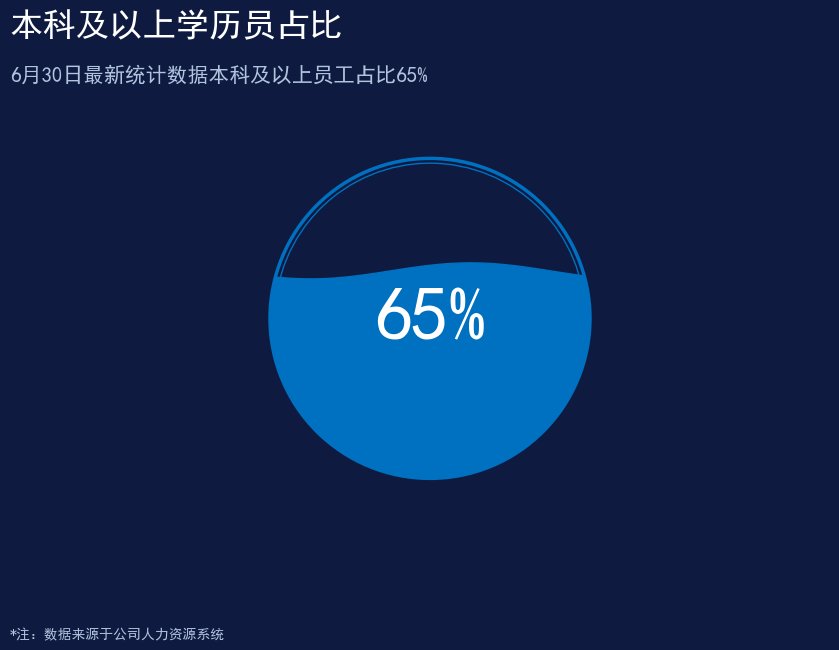

In [20]:
import matplotlib.pyplot as plt
import numpy as np
# ============================================================
# 图16：波浪水球图（匹配原图横向比例）
# ============================================================
# 【修改1】恢复横向画布比例 10:7 (宽高比约1.43，接近原图)
fig16, ax16 = plt.subplots(figsize=(10, 7), facecolor='#0E1A40')
ax16.set_facecolor('#0E1A40')

# 【修改2】重新设置坐标轴范围，保证圆形比例完美且占据视觉中心
ax16.set_xlim(-2.5, 2.5)
ax16.set_ylim(-1.75, 1.75)
ax16.set_aspect('equal')
ax16.axis('off')

# --- 1. 准备裁剪区域（正圆形） ---
clip_circle = plt.Circle((0, 0), 1.0, transform=ax16.transData)

# --- 2. 绘制波浪水面 ---
x = np.linspace(-1, 1, 1000)
y_base = -1 + 2 * 0.65  # 65% 对应的基准高度为 0.3
y_wave = y_base + 0.05 * np.sin(x * np.pi + np.pi / 4)
water = ax16.fill_between(x, -1, y_wave, color='#0070C0', zorder=5)
water.set_clip_path(clip_circle)

# --- 3. 绘制外轮廓线（内外双圈，与原图一致） ---
outer_circle = plt.Circle((0, 0), 1.0, color='#0070C0', fill=False, linewidth=2.5, zorder=10)
ax16.add_patch(outer_circle)
inner_circle = plt.Circle((0, 0), 0.97, color='#0070C0', fill=False, linewidth=1, zorder=10)
ax16.add_patch(inner_circle)

# --- 4. 添加中心文字 ---
ax16.text(0, 0, '65%', ha='center', va='center', 
          color='white', fontsize=54, fontweight='bold', zorder=11)

# --- 5. 添加标题和副标题（左对齐，位于画布左上方） ---
fig16.text(0.08, 0.92, '本科及以上学历员占比', color='white', 
           fontsize=24, fontweight='bold', ha='left', va='center')

fig16.text(0.08, 0.85, '6月30日最新统计数据本科及以上员工占比65%', 
           color='#B0C4DE', fontsize=15, ha='left', va='center')

# --- 6. 添加底部注释（左下角） ---
fig16.text(0.08, 0.05, '*注：数据来源于公司人力资源系统',
           color='#B0C4DE', fontsize=10, ha='left', va='center')

# 调整边缘留白，确保元素不贴边
plt.subplots_adjust(top=0.9, bottom=0.1, left=0.05, right=0.95)

plt.show()

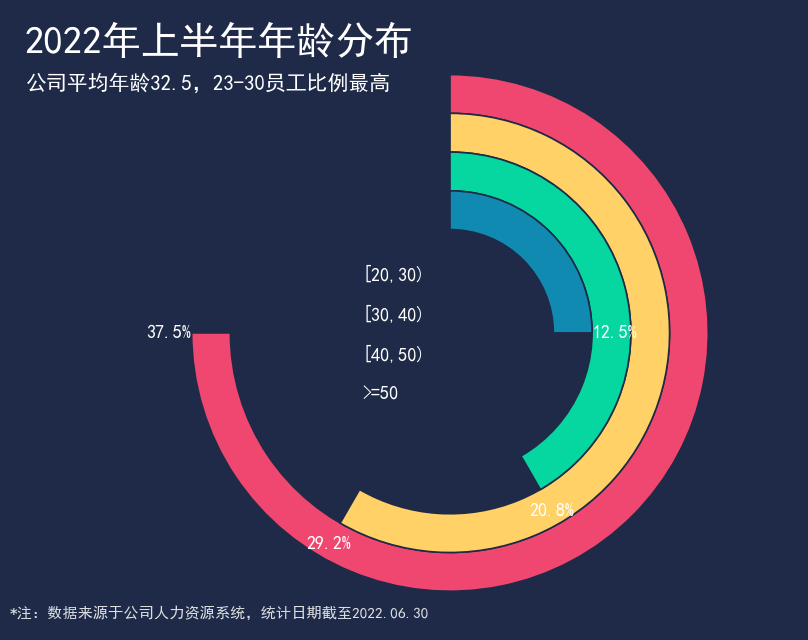

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据（来自 Excel 工作表 "17 玉玦图"） ==========
labels = ['[20,30)', '[30,40)', '[40,50)', '>=50']
ratios = [0.375, 0.2916666666666667, 0.20833333333333334, 0.125]

# 颜色（从图片取色）
colors = ['#EF476F', '#FFD166', '#06D6A0', '#118AB2']  # 红、黄、青、蓝
bg_color = '#1E2A47'      # 深蓝背景
text_color = '#FFFFFF'

# ========== 3. 计算环带角度 ==========
max_ratio = max(ratios)
# 【改动1】最大占比占满 3/4 圆（270°），其余按比例换算
extend_angles = [(r / max_ratio) * 270 for r in ratios]

# 【改动2】所有环带统一收口于正上方 12 点方向（90°），而不是右侧 3 点方向
theta2 = 90
theta1_list = [theta2 - ang for ang in extend_angles]   # -180°, -120°, -60°, 0°

# ========== 4. 半径设置（外 → 内依次嵌套） ==========
R_outer = 1.0
width = 0.15
r_outer_list = [R_outer, R_outer - width, R_outer - 2 * width, R_outer - 3 * width]

# ========== 5. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(-1.35, 1.35)
ax.set_ylim(-1.15, 1.25)
ax.set_aspect('equal')
ax.axis('off')

# ========== 6. 绘制玉玦环带 ==========
for r_out, t1, color in zip(r_outer_list, theta1_list, colors):
    wedge = Wedge(
        (0, 0), r_out, t1, theta2, width=width,
        facecolor=color, edgecolor=bg_color, linewidth=1.2
    )
    ax.add_patch(wedge)

# ========== 7. 添加百分比标签（位于各环带自由端外侧） ==========
for r_out, t1, ratio in zip(r_outer_list, theta1_list, ratios):
    angle_rad = np.radians(t1)
    label_r = r_out + 0.09
    x = label_r * np.cos(angle_rad)
    y = label_r * np.sin(angle_rad)
    ax.text(
        x, y, f'{ratio*100:.1f}%',
        color=text_color, fontsize=13, fontweight='bold',
        ha='center', va='center'
    )

# ========== 8. 年龄分组图例（移到环带中心空洞内，行距收紧） ==========
legend_x = -0.34
legend_y_start = 0.23
legend_step = 0.155
for i, label in enumerate(labels):
    y = legend_y_start - i * legend_step
    ax.text(legend_x, y, label, color=text_color, fontsize=13,
            ha='left', va='center')

# ========== 9. 标题与副标题（左上角左对齐） ==========
fig.text(0.075, 0.93, '2022年上半年年龄分布', color=text_color,
         fontsize=28, fontweight='bold', ha='left', va='center')
fig.text(0.075, 0.865, '公司平均年龄32.5，23-30员工比例最高', color=text_color,
         fontsize=15, ha='left', va='center')

# ========== 10. 底部注释 ==========
fig.text(0.06, 0.05, '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 11. 保存与显示 ==========
plt.tight_layout()
plt.savefig('玉玦图_复现.png', dpi=300, bbox_inches='tight', facecolor=bg_color)
plt.show()

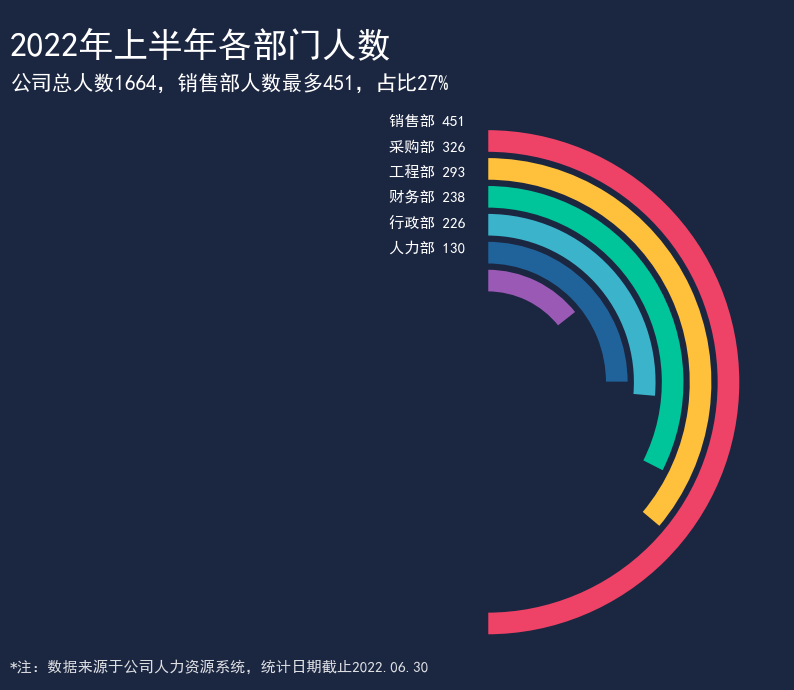

In [21]:
from matplotlib.patches import Wedge
# ========== 数据 ==========
departments = ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部']
values = [451, 326, 293, 238, 226, 130]
total = sum(values)
max_val = max(values)

colors = ['#EE4266', '#FFC13B', '#00C49A', '#3BB3CB', '#20639B', '#9B59B6']
bg_color = '#1B2641'
text_color = '#FFFFFF'

# ==========  弧长计算 ==========
max_arc = 180
arcs = [(v / max_val) * max_arc for v in values]
start_angle = 90

# ========== 环带中心与半径（关键修正：缩小 + 下移） ==========
cx, cy = 0.15, -0.15       # 环带中心下移，缩小占用空间
R_outer = 0.68             # 外半径从 1.0 缩小到 0.68
width = 0.075              # 环带宽度等比缩小
r_outer_list = [R_outer - i * width for i in range(len(values))]

# ========== 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(-0.85, 0.95)
ax.set_ylim(-0.95, 0.85)
ax.set_aspect('equal')
ax.axis('off')

# ========== 绘制跑道环带 ==========
for r_out, arc, color in zip(r_outer_list, arcs, colors):
    theta1 = start_angle - arc
    theta2 = start_angle
    wedge = Wedge(
        (cx, cy), r_out, theta1, theta2, width=width * 0.85,
        facecolor=color, edgecolor=bg_color, linewidth=1.5
    )
    ax.add_patch(wedge)

# ========== 标签（紧贴环带顶部左侧，竖直排列） ==========
# 标签顶端 = 环带顶部 (cy + R_outer) 再上移一点，恰好落在副标题下方
top_y = cy + R_outer + 0.02
for i, (dept, val) in enumerate(zip(departments, values)):
    y = top_y - i * 0.068
    ax.text(cx - 0.06, y, f'{dept} {val}',
            color=text_color, fontsize=11, fontweight='bold',
            ha='right', va='center')

# ========== 标题与副标题 ==========
fig.text(0.06, 0.93, '2022年上半年各部门人数', color=text_color,
         fontsize=25, fontweight='bold', ha='left', va='center')
fig.text(0.06, 0.875,
         f'公司总人数{total}，销售部人数最多{max_val}，占比27%',
         color=text_color, fontsize=15, ha='left', va='center')

# ========== 9. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司人力资源系统，统计日期截止2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 10. 保存与显示 ==========
plt.tight_layout()
plt.show()

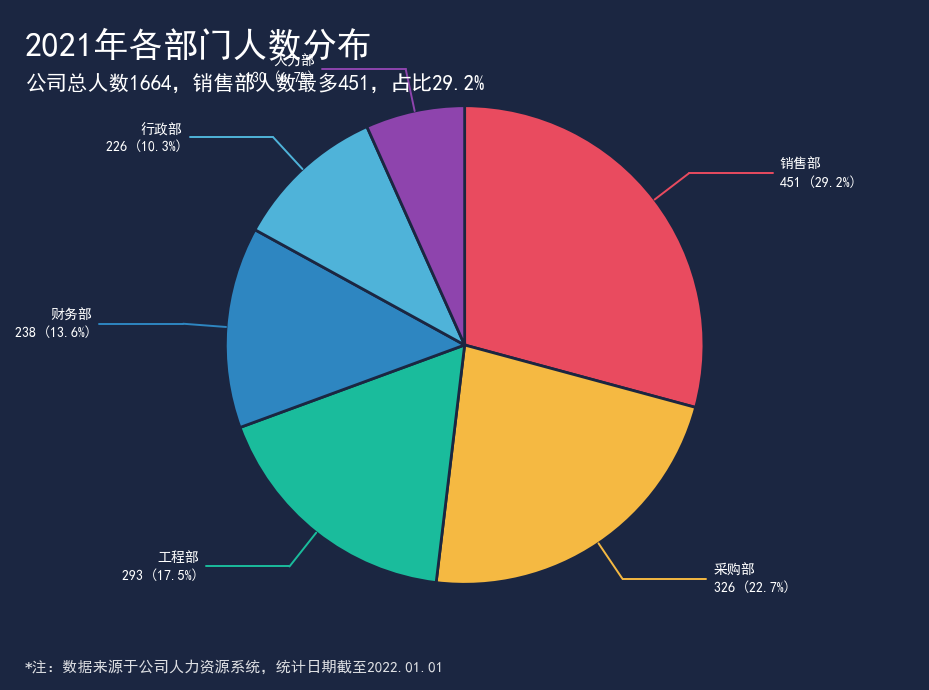

In [23]:
# ========== 2. 数据（来自 Excel 工作表 "19 南丁格尔圆饼图"） ==========
departments = ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部']
ratios = [0.292, 0.227, 0.175, 0.136, 0.103, 0.067]
values = [451, 326, 293, 238, 226, 130]

# 颜色（从图片取色，顺时针方向）
colors = ['#E94B5F', '#F5B942', '#1ABC9C', '#2E86C1', '#4FB3D9', '#8E44AD']
bg_color = '#1B2641'
text_color = '#FFFFFF'

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_aspect('equal')
ax.axis('off')

# ========== 4. 绘制饼图 ==========
wedges, _ = ax.pie(
    ratios,
    colors=colors,
    startangle=90,                 # 从 12 点钟方向开始
    counterclock=False,            # 顺时针排列
    wedgeprops=dict(edgecolor=bg_color, linewidth=2),
    radius=1.0,
)

# ========== 5. 计算每个扇区的中间角度，用于放置引导线 ==========
cumsum = np.concatenate([[0], np.cumsum(ratios)])

for i in range(len(departments)):
    a_start = 90 - cumsum[i] * 360
    a_end = 90 - cumsum[i + 1] * 360
    a_mid = (a_start + a_end) / 2
    angle_rad = np.radians(a_mid)

    # 扇区外边缘的点
    x1, y1 = np.cos(angle_rad), np.sin(angle_rad)

    # 沿径向向外延伸到 P2
    r2 = 1.18
    x2, y2 = r2 * np.cos(angle_rad), r2 * np.sin(angle_rad)

    # 水平延伸到 P3（折线第二段）
    x3 = x2 + (0.35 if x2 >= 0 else -0.35)
    y3 = y2

    # 绘制引导线（径向段 + 水平段）
    ax.plot([x1, x2], [y1, y2], color=colors[i], linewidth=1.4, solid_capstyle='round')
    ax.plot([x2, x3], [y2, y3], color=colors[i], linewidth=1.4, solid_capstyle='round')

    # 在引导线末端添加标签
    ha = 'left' if x3 > 0 else 'right'
    offset = 0.03 if x3 > 0 else -0.03
    ax.text(
        x3 + offset, y3,
        f'{departments[i]}\n{values[i]} ({ratios[i]*100:.1f}%)',
        color=text_color, fontsize=10, fontweight='bold',
        ha=ha, va='center', linespacing=1.4
    )

# ========== 6. 标题与副标题 ==========
fig.text(0.06, 0.93, '2021年各部门人数分布', color=text_color,
         fontsize=25, fontweight='bold', ha='left', va='center')
fig.text(0.06, 0.875,
         '公司总人数1664，销售部人数最多451，占比29.2%',
         color=text_color, fontsize=15, ha='left', va='center')

# ========== 7. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司人力资源系统，统计日期截至2022.01.01',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 8. 视口范围（给外部标签留出空间） ==========
ax.set_xlim(-1.9, 1.9)
ax.set_ylim(-1.4, 1.4)

# ========== 9. 保存与显示 ==========
plt.tight_layout()
plt.show()

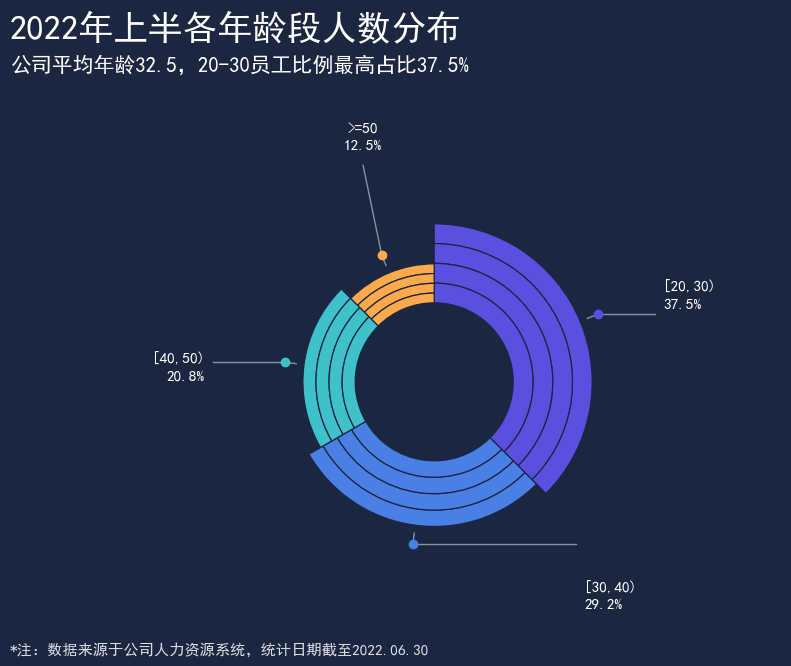

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
labels = ['[20,30)', '[30,40)', '[40,50)', '>=50']
ratios = [0.375, 0.2916666666666667, 0.20833333333333334, 0.125]
colors = ['#5B4FE0', '#4A7FE5', '#3FC1C9', '#FFA94D']  # 紫、蓝、青、橙
bg_color = '#1B2641'
text_color = '#FFFFFF'

# ========== 3. 扇区角度（从顶部 90° 开始顺时针） ==========
start = 90
sectors = []
cum = 0.0
for r in ratios:
    a1 = start - cum * 360
    cum += r
    a2 = start - cum * 360
    sectors.append((a2, a1))   # (theta1, theta2)

# ========== 4. 半径映射（关键修正：外半径随占比变化） ==========
r_inner = 0.50                 # 所有扇区共用内半径（中心孔）
r_min = 0.62                   # 最小占比对应的外半径
r_max = 1.00                   # 最大占比对应的外半径
ratio_max = max(ratios)

def outer_radius(r):
    """外半径按占比线性映射到 [r_min, r_max]"""
    return r_min + (r / ratio_max) * (r_max - r_min)

r_outer_list = [outer_radius(r) for r in ratios]
n_layers = 4   # 每个扇区内部的同心细分层数

# ========== 5. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_aspect('equal')
ax.axis('off')

# ========== 6. 绘制扇形（每个扇区的外半径不同） ==========
for (t1, t2), color, r_out in zip(sectors, colors, r_outer_list):
    total_w = r_out - r_inner
    lw = total_w / n_layers
    for j in range(n_layers):
        ro = r_out - j * lw
        wedge = Wedge((0, 0), ro, t1, t2, width=lw,
                      facecolor=color, edgecolor=bg_color, linewidth=0.9)
        ax.add_patch(wedge)

# ========== 7. 引导线 + 标签 ==========
# 计算每个扇区弧中点（角度），用于连接引导线
guide_style = [
    # (标签位置, 水平对齐, 圆点延伸方向)
    ((1.45, 0.55), 'left',  'right'),    # 右上 [20,30)
    ((0.95, -1.35), 'left',  'right'),   # 右下 [30,40)
    ((-1.45, 0.10), 'right', 'left'),    # 左中 [40,50)
    ((-0.45, 1.55), 'center', 'up'),     # 上方 >=50
]

for i, ((t1, t2), color, r_out) in enumerate(zip(sectors, colors, r_outer_list)):
    a_mid = np.radians((t1 + t2) / 2)
    # 从扇区外缘中点向外延伸的连接点
    r_connect = r_out + 0.05
    x1, y1 = r_connect * np.cos(a_mid), r_connect * np.sin(a_mid)
    # 圆点位置（再向外一点）
    r_dot = r_out + 0.12
    xd, yd = r_dot * np.cos(a_mid), r_dot * np.sin(a_mid)

    label_pos, ha, direction = guide_style[i]

    # 第一段：扇区外缘 → 圆点
    ax.plot([x1, xd], [y1, yd], color='#8892A6', linewidth=1.0, zorder=5)

    # 第二段：圆点 → 标签方向
    if ha == 'left':
        ax.plot([xd, label_pos[0] - 0.05], [yd, yd],
                color='#8892A6', linewidth=1.0, zorder=5)
    elif ha == 'right':
        ax.plot([xd, label_pos[0] + 0.05], [yd, yd],
                color='#8892A6', linewidth=1.0, zorder=5)
    else:  # center：向上
        ax.plot([xd, label_pos[0]], [yd, label_pos[1] - 0.18],
                color='#8892A6', linewidth=1.0, zorder=5)

    # 拐点彩色圆点
    ax.plot(xd, yd, 'o', color=color, markersize=6,
            zorder=6, markeredgecolor=color)

    # 标签文本
    ax.text(label_pos[0], label_pos[1],
            f'{labels[i]}\n{ratios[i]*100:.1f}%',
            color=text_color, fontsize=11, fontweight='bold',
            ha=ha, va='center', linespacing=1.5, zorder=7)

# ========== 8. 标题与副标题 ==========
fig.text(0.06, 0.93, '2022年上半各年龄段人数分布', color=text_color,
         fontsize=25, fontweight='bold', ha='left', va='center')
fig.text(0.06, 0.875,
         '公司平均年龄32.5，20-30员工比例最高占比37.5%',
         color=text_color, fontsize=15, ha='left', va='center')

# ========== 9. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司人力资源系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 10. 视口范围 ==========
ax.set_xlim(-2.0, 2.2)
ax.set_ylim(-1.6, 1.9)
plt.subplots_adjust(left=0.02, right=0.98, top=0.85, bottom=0.06)

# ========== 11. 保存与显示 ==========
plt.show()

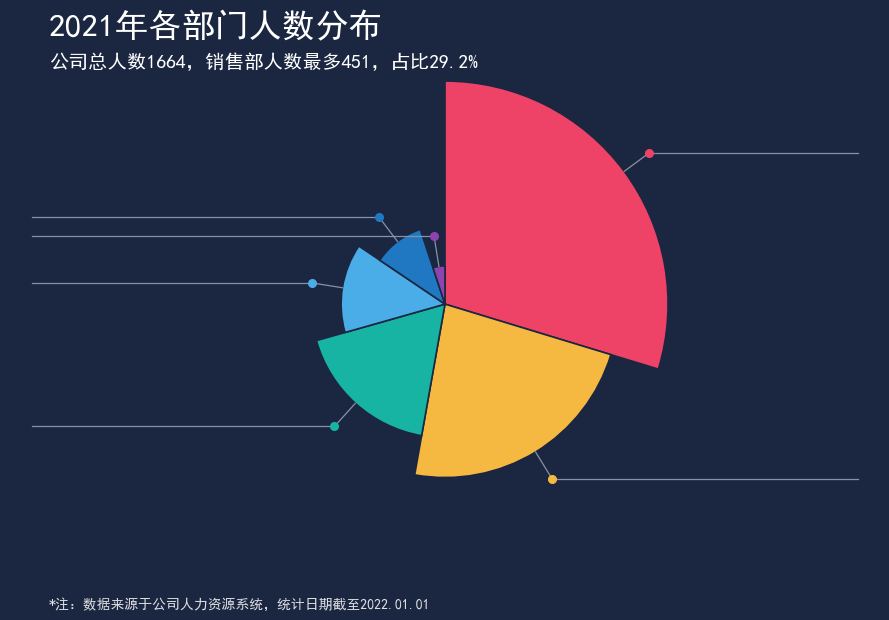

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
departments = ['销售部', '采购部', '工程部', '财务部', '行政部', '人力部']
ratios = [0.292, 0.227, 0.175, 0.136, 0.103, 0.05]
colors = ['#EE4266', '#F5B942', '#17B3A3', '#4AADE8', '#1F78C1', '#8E44AD']
bg_color = '#1B2641'
text_color = '#FFFFFF'

# ========== 3. 计算角度与半径 ==========
total = sum(ratios)
angles = [r / total * 360 for r in ratios]
max_r = 1.0
r_values = [r / max(ratios) * max_r for r in ratios]

# ========== 4. 起止角度（从顶部 90° 开始顺时针） ==========
start_angle = 90
sectors = []
cum = 0.0
for ang in angles:
    theta1 = start_angle - (cum + ang)
    theta2 = start_angle - cum
    sectors.append((theta1, theta2))
    cum += ang

# ========== 5. 创建画布 ==========
fig, ax = plt.subplots(figsize=(9, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_aspect('equal')
ax.axis('off')

# ========== 6. 绘制扇区 ==========
for (t1, t2), color, r in zip(sectors, colors, r_values):
    wedge = Wedge(
        (0, 0), r, t1, t2,
        facecolor=color, edgecolor=bg_color, linewidth=1.2
    )
    ax.add_patch(wedge)

# ========== 7. 引导线（折线：斜线 + 水平线，末端无文字） ==========
line_color = '#8892A6'

for (t1, t2), color, r in zip(sectors, colors, r_values):
    mid_angle = np.radians((t1 + t2) / 2)

    # 扇区外缘中点 → 圆点（斜线段）
    x0, y0 = r * np.cos(mid_angle), r * np.sin(mid_angle)
    r_dot = r + 0.14
    xd, yd = r_dot * np.cos(mid_angle), r_dot * np.sin(mid_angle)
    ax.plot([x0, xd], [y0, yd], color=line_color, linewidth=0.9, zorder=5)

    # 彩色圆点
    ax.plot(xd, yd, 'o', color=color, markersize=5.5,
            zorder=6, markeredgecolor=color)

    # 圆点 → 水平延长线（折线第二段）
    x_end = 1.85 if xd >= 0 else -1.85
    ax.plot([xd, x_end], [yd, yd], color=line_color,
            linewidth=0.9, zorder=5)

# ========== 8. 标题与副标题 ==========
fig.text(0.06, 0.93, '2021年各部门人数分布', color=text_color,
         fontsize=24, fontweight='bold', ha='left', va='center')
fig.text(0.06, 0.875,
         '公司总人数1664，销售部人数最多451，占比29.2%',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 9. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司人力资源系统，统计日期截至2022.01.01',
         color=text_color, fontsize=10, ha='left', va='center', alpha=0.85)

# ========== 10. 视口范围 ==========
ax.set_xlim(-1.95, 1.95)
ax.set_ylim(-1.30, 1.30)

# ========== 11. 保存与显示 ==========
plt.tight_layout()
plt.savefig('南丁格尔PPT_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

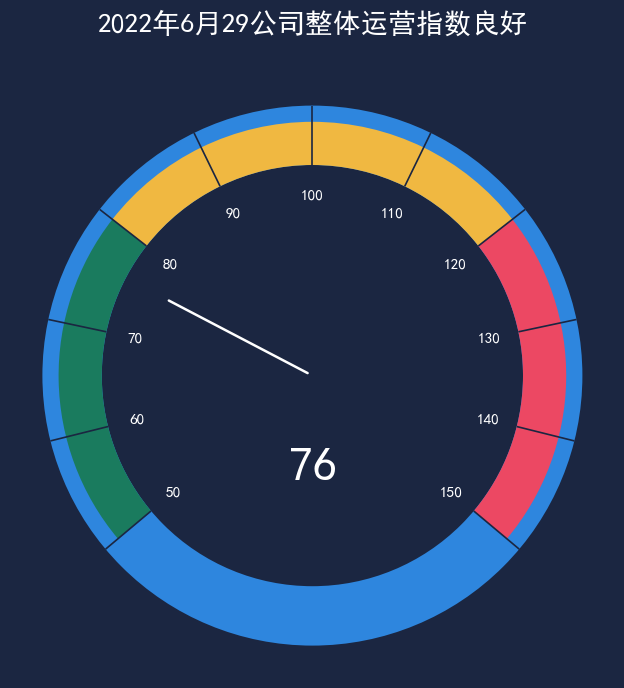

In [25]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Wedge

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 基础参数 ==========
bg_color = '#1B2641'
text_color = '#FFFFFF'
blue_color = '#2E86DE'      # 外层蓝色圆环

r_outer = 1.00              # 蓝色圆环外半径
r_blue_inner = 0.78         # 圆环内沿（彩色弧带内沿与之齐平，内侧不留蓝）
r_color_outer = 0.94        # 彩色弧带外半径（外侧保留一圈蓝色）
r_num = 0.67                # 刻度数字半径
pointer_value = 76

GAUGE_SPAN = 260            # 刻度 50~150 覆盖的圆心角（度）

def val_to_angle(v):
    """值 → 角度：100 固定在正上方 90°，50/150 关于竖直轴对称"""
    return 90 + (100 - v) / 100.0 * GAUGE_SPAN

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(8.5, 7.2))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_aspect('equal')
ax.axis('off')

# ========== 4. 外层：蓝色圆环（360° 整圆） ==========
ax.add_patch(plt.Circle((0, 0), r_outer,
                        facecolor=blue_color, edgecolor='none', zorder=1))
# 内孔用背景色补出，形成圆环
ax.add_patch(plt.Circle((0, 0), r_blue_inner,
                        facecolor=bg_color, edgecolor='none', zorder=1.5))

# ========== 5. 内层：三色弧带（内沿与环内沿齐平，只在外侧留蓝） ==========
zones = [
    (50, 80, '#1A7B5E'),    # 青绿色
    (80, 120, '#F0B841'),   # 黄色
    (120, 150, '#EC4863'),  # 红色
]

for v1, v2, color in zones:
    t1 = val_to_angle(v2)   # 较小角度（起始）
    t2 = val_to_angle(v1)   # 较大角度（结束）
    w = Wedge(
        (0, 0), r_color_outer, t1, t2,
        width=r_color_outer - r_blue_inner,   # 关键：内沿 = 环内沿
        facecolor=color, edgecolor='none', zorder=2
    )
    ax.add_patch(w)

# ========== 6. 径向刻度线（贯穿整个环带） ==========
for v in range(50, 151, 10):
    a = np.radians(val_to_angle(v))
    x1, y1 = r_blue_inner * np.cos(a), r_blue_inner * np.sin(a)
    x2, y2 = r_outer * np.cos(a), r_outer * np.sin(a)
    ax.plot([x1, x2], [y1, y2], color=bg_color,
            linewidth=1.2, zorder=3, solid_capstyle='butt')

# ========== 7. 刻度数字 ==========
for v in range(50, 151, 10):
    a = np.radians(val_to_angle(v))
    x = r_num * np.cos(a)
    y = r_num * np.sin(a)
    ax.text(x, y, str(v), color=text_color, fontsize=11,
            ha='center', va='center', fontweight='bold', zorder=6)

# ========== 8. 指针 ==========
pa = np.radians(val_to_angle(pointer_value))
ax.plot(
    [0.02 * np.cos(pa), 0.60 * np.cos(pa)],
    [0.02 * np.sin(pa), 0.60 * np.sin(pa)],
    color='#FFFFFF', linewidth=1.8,
    solid_capstyle='round', zorder=7
)

# ========== 9. 中心数值 ==========
ax.text(0, -0.34, str(pointer_value), color=text_color,
        fontsize=34, fontweight='bold',
        ha='center', va='center', zorder=6)

# ========== 10. 标题 ==========
fig.text(0.5, 0.95, '2022年6月29公司整体运营指数良好',
         color=text_color, fontsize=20, fontweight='bold',
         ha='center', va='center')

# ========== 11. 视口与保存 ==========
ax.set_xlim(-1.12, 1.12)
ax.set_ylim(-1.12, 1.12)
plt.subplots_adjust(left=0.04, right=0.96, top=0.88, bottom=0.04)

plt.savefig('仪表盘图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

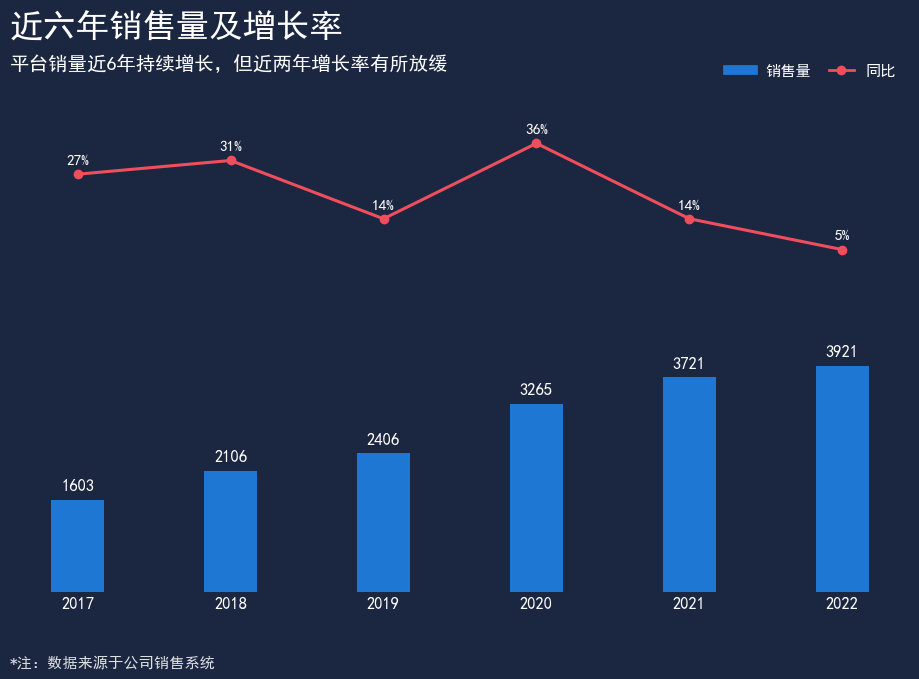

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
years = [2017, 2018, 2019, 2020, 2021, 2022]
sales = [1603, 2106, 2406, 3265, 3721, 3921]
# 同比（2017 年补上 27%）
growth = [27, 31, 14, 36, 14, 5]

bar_color = '#1F77D4'
line_color = '#F04E5C'
bg_color = '#1B2641'
text_color = '#FFFFFF'

# ========== 3. 创建画布（用 add_axes 手动定位两个区域） ==========
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)

# 柱状图区（下部）与折线图区（上部）—— 高度比 ≈ 6:4，中间留空隙
ax_bar  = fig.add_axes([0.06, 0.13, 0.90, 0.42])
ax_line = fig.add_axes([0.06, 0.58, 0.90, 0.24], sharex=ax_bar)

for a in (ax_bar, ax_line):
    a.set_facecolor(bg_color)
    for s in a.spines.values():
        s.set_visible(False)

x = np.arange(len(years))

# ========== 4. 绘制柱状图（下部） ==========
ax_bar.bar(x, sales, width=0.35, color=bar_color, zorder=3)
for xi, v in zip(x, sales):
    ax_bar.text(xi, v + 120, str(v), color=text_color,
                fontsize=12, ha='center', va='bottom', zorder=5)

ax_bar.set_ylim(0, max(sales) * 1.30)
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(years, color=text_color, fontsize=12)
ax_bar.set_yticks([])
ax_bar.tick_params(axis='x', length=0)

# ========== 5. 绘制折线图（上部） ==========
ax_line.plot(x, growth, color=line_color, linewidth=2.2,
             marker='o', markersize=6,
             markerfacecolor=line_color, markeredgecolor=line_color,
             zorder=4)
for xi, v in zip(x, growth):
    ax_line.text(xi, v + 2.2, f'{v}%', color=text_color,
                 fontsize=11, ha='center', va='bottom', zorder=5)

ax_line.set_ylim(min(growth) - 8, max(growth) + 10)
ax_line.set_yticks([])
ax_line.tick_params(axis='x', length=0)
# 隐藏上部区域的 x 轴刻度标签（共享 x 轴，只在下部显示）
plt.setp(ax_line.get_xticklabels(), visible=False)

# ========== 6. 图例（右上角） ==========
legend_elements = [
    Line2D([0], [0], color=bar_color, lw=7, label='销售量'),
    Line2D([0], [0], color=line_color, lw=2,
           marker='o', markersize=6, label='同比'),
]
ax_line.legend(handles=legend_elements, loc='upper right',
               bbox_to_anchor=(1.0, 1.35), frameon=False,
               labelcolor=text_color, fontsize=11, ncol=2,
               handlelength=1.6, columnspacing=1.2)

# ========== 7. 标题与副标题 ==========
fig.text(0.06, 0.94, '近六年销售量及增长率', color=text_color,
         fontsize=24, fontweight='bold', ha='left', va='center')
fig.text(0.06, 0.885,
         '平台销量近6年持续增长，但近两年增长率有所放缓',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 8. 底部注释 ==========
fig.text(0.06, 0.03, '*注：数据来源于公司销售系统',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 9. 保存与显示 ==========
plt.savefig('柱形折线图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

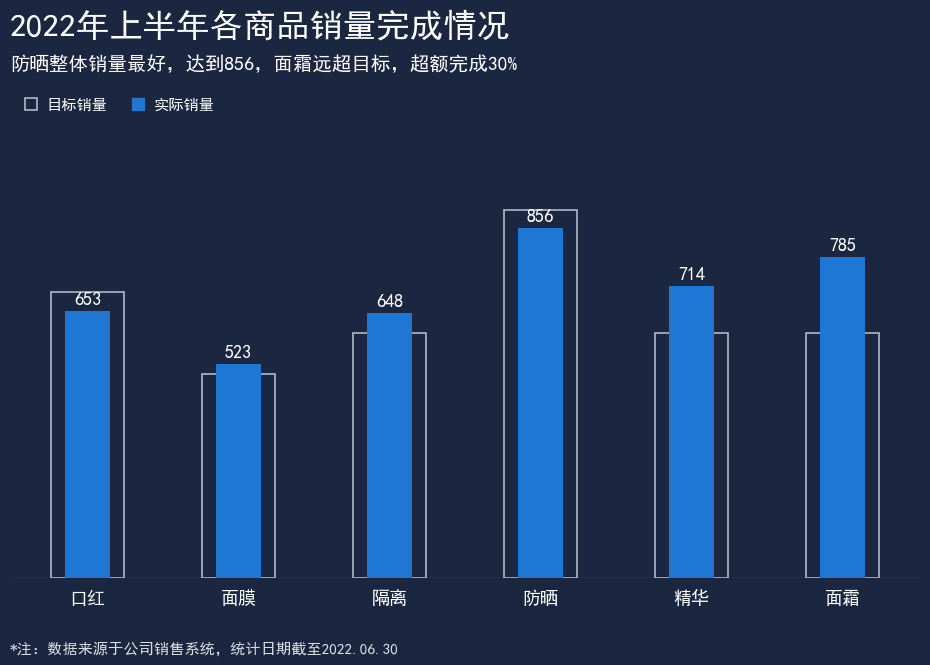

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
products = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
actual   = [653, 523, 648, 856, 714, 785]
target   = [700, 500, 600, 900, 600, 600]

bg_color      = '#1B2641'
text_color    = '#FFFFFF'
bar_color     = '#1F77D4'      # 实际销量（蓝色）
outline_color = '#B0B8C8'      # 目标销量（灰色轮廓）

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(products))
target_width  = 0.48    # 目标柱（宽，灰色轮廓）
actual_width  = 0.30    # 实际柱（窄，蓝色实心），两侧留空隙

# ========== 4. 绘制目标柱（宽，灰色轮廓） ==========
ax.bar(x, target, width=target_width,
       facecolor='none', edgecolor=outline_color,
       linewidth=1.2, zorder=2)

# ========== 5. 绘制实际柱（窄，蓝色实心） ==========
ax.bar(x, actual, width=actual_width,
       facecolor=bar_color, edgecolor='none', zorder=3)

# ========== 6. 数值标签（紧贴实际柱顶） ==========
for xi, v in zip(x, actual):
    ax.text(xi, v + 12, str(v), color=text_color,
            fontsize=13, ha='center', va='bottom', zorder=5)

# ========== 7. 底部基线 ==========
ax.axhline(0, color='#3A4A6B', linewidth=1.0, zorder=1)

# ========== 8. 坐标轴样式 ==========
ax.set_ylim(0, max(target) * 1.22)
ax.set_xticks(x)
ax.set_xticklabels(products, color=text_color, fontsize=13)
ax.set_yticks([])
ax.tick_params(axis='x', length=0, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)

# ========== 9. 标题与副标题 ==========
fig.text(0.06, 0.93, '2022年上半年各商品销量完成情况',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.875,
         '防晒整体销量最好，达到856，面霜远超目标，超额完成30%',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 10. 图例（副标题正下方，横排） ==========
legend_elements = [
    Line2D([0], [0], marker='s', color='none',
           markerfacecolor='none', markeredgecolor=outline_color,
           markeredgewidth=1.2, markersize=9, label='目标销量'),
    Line2D([0], [0], marker='s', color='none',
           markerfacecolor=bar_color, markeredgecolor=bar_color,
           markersize=9, label='实际销量'),
]
fig.legend(handles=legend_elements, loc='upper left',
           bbox_to_anchor=(0.06, 0.845), frameon=False,
           labelcolor=text_color, fontsize=11, ncol=2,
           handlelength=1.0, columnspacing=1.5, handletextpad=0.5)

# ========== 11. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 12. 布局与保存 ==========
plt.subplots_adjust(left=0.06, right=0.97, top=0.78, bottom=0.14)
plt.savefig('目标柱形图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

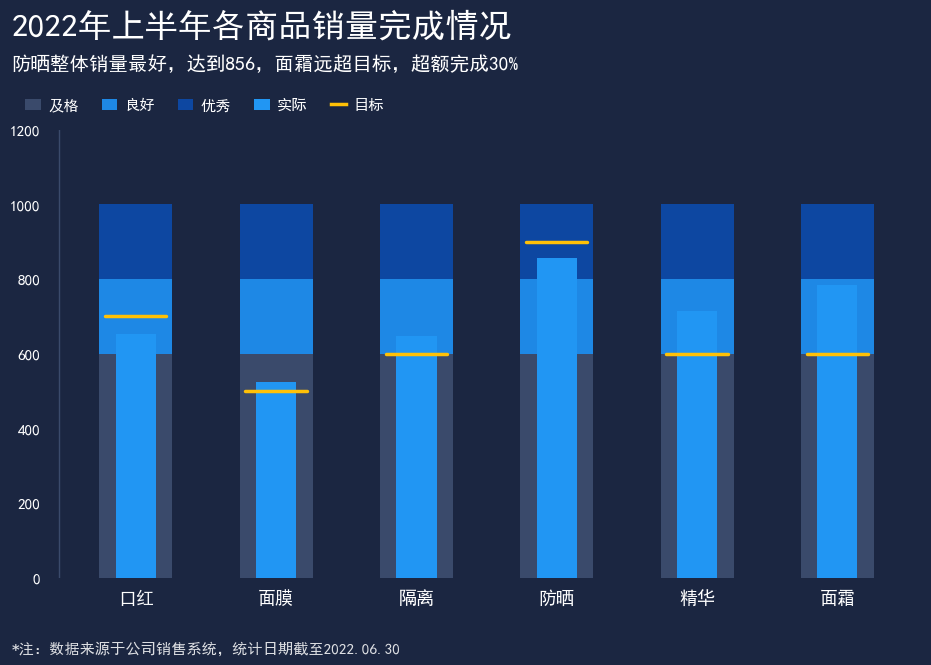

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据（来自 Excel 工作表 "25 子弹图"） ==========
products = ['口红', '面膜', '隔离', '防晒', '精华', '面霜']
actual   = [653, 523, 648, 856, 714, 785]
target   = [700, 500, 600, 900, 600, 600]

# 三段背景区间：及格 0~600，良好 600~800，优秀 800~1000
pass_val   = 600
good_val   = 200     # 600 → 800
excellent  = 200     # 800 → 1000

bg_color     = '#1B2641'
text_color   = '#FFFFFF'
pass_color   = '#3A4A6B'    # 及格：深灰蓝
good_color   = '#1E88E5'    # 良好：中蓝
excel_color  = '#0D47A1'    # 优秀：深蓝
actual_color = '#2196F3'    # 实际：亮蓝
target_color = '#FFC107'    # 目标：黄色

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(products))
bar_width = 0.52

# ========== 4. 背景三段堆叠柱 ==========
# 第一段：及格（0 ~ 600）
ax.bar(x, [pass_val]*len(x), width=bar_width,
       color=pass_color, edgecolor='none', zorder=2)

# 第二段：良好（600 ~ 800）
ax.bar(x, [good_val]*len(x), bottom=[pass_val]*len(x),
       width=bar_width, color=good_color, edgecolor='none', zorder=2)

# 第三段：优秀（800 ~ 1000）
ax.bar(x, [excellent]*len(x),
       bottom=[pass_val + good_val]*len(x),
       width=bar_width, color=excel_color, edgecolor='none', zorder=2)

# ========== 5. 前景实际销量柱（窄一点，居中） ==========
ax.bar(x, actual, width=bar_width * 0.55,
       color=actual_color, edgecolor='none', zorder=3)

# ========== 6. 目标标记（黄色短横线，略宽于柱） ==========
for xi, t in zip(x, target):
    ax.plot([xi - bar_width * 0.42, xi + bar_width * 0.42], [t, t],
            color=target_color, linewidth=2.5,
            solid_capstyle='round', zorder=4)

# ========== 7. 坐标轴样式 ==========
ax.set_ylim(0, 1200)
ax.set_xlim(-0.6, len(products) - 0.4)
ax.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax.set_yticklabels(['0', '200', '400', '600', '800', '1000', '1200'],
                   color=text_color, fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(products, color=text_color, fontsize=13)
ax.tick_params(axis='x', length=0, pad=8)
ax.tick_params(axis='y', length=0, pad=8)

# 左侧浅灰轴
ax.axvline(-0.55, color='#3A4A6B', linewidth=1.0, zorder=1)
for spine in ax.spines.values():
    spine.set_visible(False)

# ========== 8. 图例（副标题下方，横排） ==========
legend_elements = [
    Patch(facecolor=pass_color,   label='及格'),
    Patch(facecolor=good_color,   label='良好'),
    Patch(facecolor=excel_color,  label='优秀'),
    Patch(facecolor=actual_color, label='实际'),
    Line2D([0], [0], color=target_color, linewidth=2.5, label='目标'),
]
fig.legend(handles=legend_elements, loc='upper left',
           bbox_to_anchor=(0.06, 0.845), frameon=False,
           labelcolor=text_color, fontsize=11, ncol=5,
           handlelength=1.0, columnspacing=1.5, handletextpad=0.5)

# ========== 9. 标题与副标题 ==========
fig.text(0.06, 0.93, '2022年上半年各商品销量完成情况',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.875,
         '防晒整体销量最好，达到856，面霜远超目标，超额完成30%',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 10. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 11. 布局与保存 ==========
plt.subplots_adjust(left=0.10, right=0.97, top=0.78, bottom=0.14)
plt.savefig('子弹图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

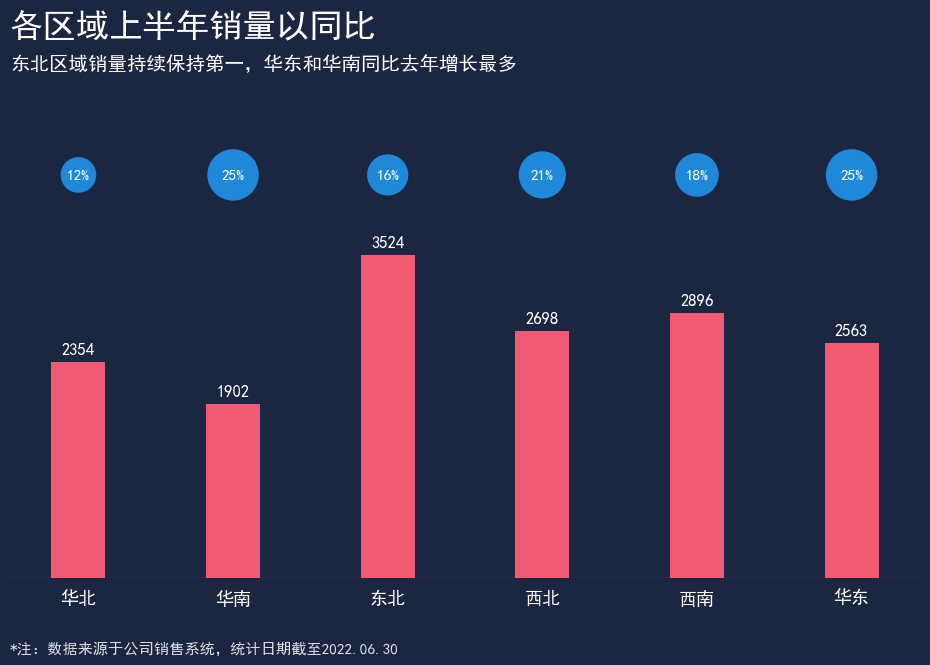

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales   = [2354, 1902, 3524, 2698, 2896, 2563]
growth  = [0.12, 0.25, 0.16, 0.21, 0.18, 0.25]

bg_color     = '#1B2641'
text_color   = '#FFFFFF'
bar_color    = '#F05A73'
circle_color = '#2088D8'

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

x = np.arange(len(regions))
bar_width = 0.35

# ========== 4. 绘制柱形图 ==========
ax.bar(x, sales, width=bar_width, color=bar_color,
       edgecolor='none', zorder=3)

# ========== 5. 柱顶数值标签 ==========
for xi, v in zip(x, sales):
    ax.text(xi, v + 60, str(v), color=text_color,
            fontsize=12, ha='center', va='bottom', zorder=5)

# ========== 6. 蓝色圆圈 + 百分比（统一水平线） ==========
CIRCLE_Y = 4400                 # 所有圆圈共用同一 y 坐标
for xi, pct in zip(x, growth):
    ax.scatter(xi, CIRCLE_Y, s=pct * 5500, color=circle_color,
               edgecolor='none', zorder=6)
    ax.text(xi, CIRCLE_Y, f'{pct*100:.0f}%', color=text_color,
            fontsize=11, ha='center', va='center',
            fontweight='bold', zorder=7)

# ========== 7. 底部基线 ==========
ax.axhline(0, color='#3A4A6B', linewidth=1.0, zorder=1)

# ========== 8. 坐标轴样式 ==========
ax.set_ylim(0, 5200)            # 提高上限，给统一高度的圆圈留空间
ax.set_xticks(x)
ax.set_xticklabels(regions, color=text_color, fontsize=13)
ax.set_yticks([])
ax.tick_params(axis='x', length=0, pad=8)
for spine in ax.spines.values():
    spine.set_visible(False)

# ========== 9. 标题与副标题 ==========
fig.text(0.06, 0.93, '各区域上半年销量以同比',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.875,
         '东北区域销量持续保持第一，华东和华南同比去年增长最多',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 10. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 11. 布局与保存 ==========
plt.subplots_adjust(left=0.06, right=0.97, top=0.82, bottom=0.14)
plt.savefig('柱形圆_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

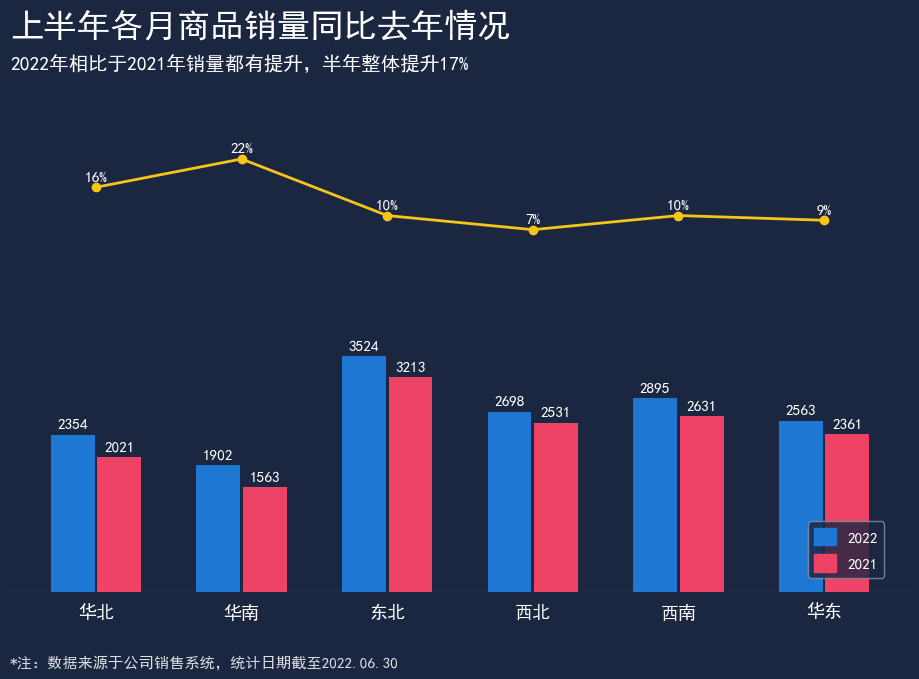

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据（来自 Excel 工作表 "27 簇状柱形折线图"） ==========
regions = ['华北', '华南', '东北', '西北', '西南', '华东']
sales_2022 = [2354, 1902, 3524, 2698, 2895, 2563]
sales_2021 = [2021, 1563, 3213, 2531, 2631, 2361]
growth_pct = [16, 22, 10, 7, 10, 9]    # 同比增长（%）

bg_color      = '#1B2641'
text_color    = '#FFFFFF'
bar_2022      = '#1F77D4'      # 2022 蓝色
bar_2021      = '#EE4266'      # 2021 红色
line_color    = '#F5C518'      # 增长率折线黄色

# ========== 3. 创建画布（两区域：上部折线 + 下部柱形） ==========
fig = plt.figure(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)

# 柱形区（下部）
ax_bar = fig.add_axes([0.06, 0.13, 0.90, 0.42])
# 折线区（上部）
ax_line = fig.add_axes([0.06, 0.60, 0.90, 0.20], sharex=ax_bar)

for a in (ax_bar, ax_line):
    a.set_facecolor(bg_color)
    for s in a.spines.values():
        s.set_visible(False)

x = np.arange(len(regions))
bar_width = 0.30

# ========== 4. 绘制簇状柱形（下部） ==========
# 2022 柱：左移
ax_bar.bar(x - bar_width/2 - 0.01, sales_2022, width=bar_width,
           color=bar_2022, edgecolor='none', zorder=3)
# 2021 柱：右移
ax_bar.bar(x + bar_width/2 + 0.01, sales_2021, width=bar_width,
           color=bar_2021, edgecolor='none', zorder=3)

# 柱顶数值标签
for xi, v in zip(x, sales_2022):
    ax_bar.text(xi - bar_width/2 - 0.01, v + 60, str(v),
                color=text_color, fontsize=11,
                ha='center', va='bottom', zorder=5)
for xi, v in zip(x, sales_2021):
    ax_bar.text(xi + bar_width/2 + 0.01, v + 60, str(v),
                color=text_color, fontsize=11,
                ha='center', va='bottom', zorder=5)

# 底部基线
ax_bar.axhline(0, color='#3A4A6B', linewidth=1.0, zorder=1)

# 柱形区坐标轴样式
ax_bar.set_ylim(0, max(sales_2022) * 1.25)
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(regions, color=text_color, fontsize=13)
ax_bar.set_yticks([])
ax_bar.tick_params(axis='x', length=0, pad=8)

# ========== 5. 绘制折线（上部） ==========
ax_line.plot(x, growth_pct, color=line_color, linewidth=2.0,
             marker='o', markersize=6,
             markerfacecolor=line_color, markeredgecolor=line_color,
             zorder=4)

# 折线点数值标签
for xi, v in zip(x, growth_pct):
    ax_line.text(xi, v + 0.9, f'{v}%', color=text_color,
                 fontsize=11, ha='center', va='bottom', zorder=5)

# 折线区样式
ax_line.set_ylim(0, max(growth_pct) * 1.35)
ax_line.set_yticks([])
ax_line.tick_params(axis='x', length=0)
plt.setp(ax_line.get_xticklabels(), visible=False)   # 隐藏折线区 x 标签

# ========== 6. 图例（右下角，带彩色边框） ==========
legend_elements = [
    Patch(facecolor=bar_2022, edgecolor=bar_2022, label='2022'),
    Patch(facecolor=bar_2021, edgecolor=bar_2021, label='2021'),
]
ax_bar.legend(handles=legend_elements, loc='lower right',
              bbox_to_anchor=(0.98, 0.02), frameon=True,
              facecolor=bg_color, edgecolor='#8892A6',
              labelcolor=text_color, fontsize=11,
              handlelength=1.4, handleheight=1.4,
              labelspacing=0.6)

# ========== 7. 标题与副标题 ==========
fig.text(0.06, 0.94, '上半年各月商品销量同比去年情况',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.885,
         '2022年相比于2021年销量都有提升，半年整体提升17%',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 8. 底部注释 ==========
fig.text(0.06, 0.03,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 9. 保存与显示 ==========
plt.savefig('簇状柱形折线图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

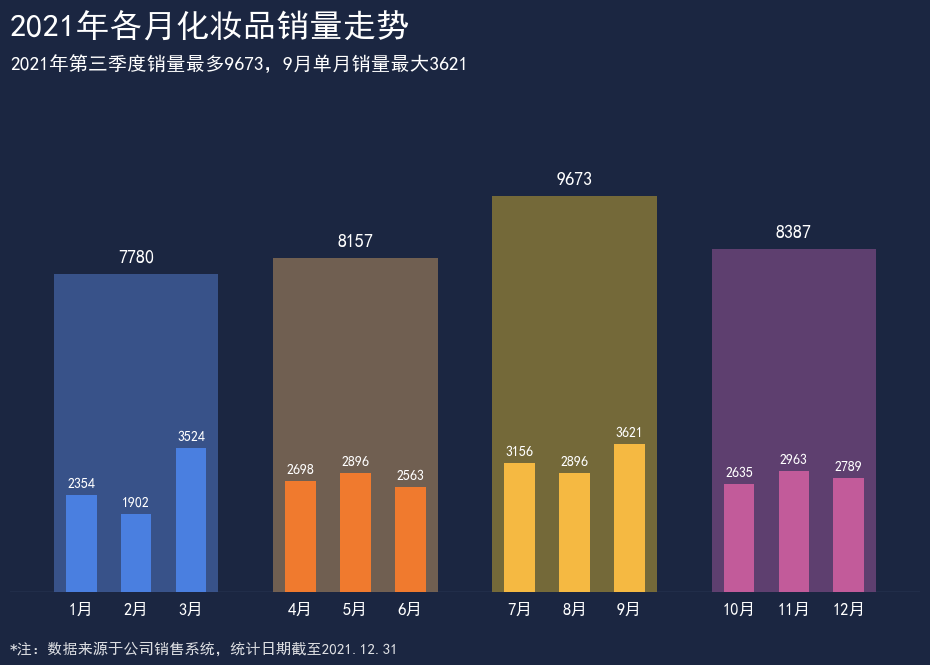

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据（来自 Excel 工作表 "28 复合柱形图"） ==========
months = ['1月', '2月', '3月', '4月', '5月', '6月',
          '7月', '8月', '9月', '10月', '11月', '12月']
sales = [2354, 1902, 3524, 2698, 2896, 2563,
         3156, 2896, 3621, 2635, 2963, 2789]
quarter_sums = [7780, 8157, 9673, 8387]

bg_color    = '#1B2641'
text_color  = '#FFFFFF'

# 季度背景色 / 月份柱色
q_bg_colors = ['#3E5A96', '#806A55', '#857538', '#6B4478']
m_bar_colors = ['#4A7FE0', '#F07A2E', '#F5B942', '#C25B9A']

# ========== 3. 位置布局（季度之间留大间隔） ==========
# 每个月柱中心位置，每季度 3 个月柱间距 0.5
month_x = [0, 0.5, 1.0,
           2.0, 2.5, 3.0,
           4.0, 4.5, 5.0,
           6.0, 6.5, 7.0]
quarter_x = [0.5, 2.5, 4.5, 6.5]

bar_width = 0.28   # 月份柱宽
bg_width  = 1.5    # 季度背景柱宽

# ========== 4. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

max_y = max(quarter_sums) * 1.18

# ========== 5. 绘制季度背景柱（含季度总和标签） ==========
for qx, qsum, bgc in zip(quarter_x, quarter_sums, q_bg_colors):
    ax.bar(qx, qsum, width=bg_width, color=bgc,
           edgecolor='none', alpha=0.85, zorder=2)
    ax.text(qx, qsum + max_y * 0.020, str(qsum),
            color=text_color, fontsize=13,
            ha='center', va='bottom', zorder=5)

# ========== 6. 绘制月份柱（含月份标签） ==========
# 每个月份对应的颜色（按季度分组）
month_colors = ([m_bar_colors[0]] * 3 +
                [m_bar_colors[1]] * 3 +
                [m_bar_colors[2]] * 3 +
                [m_bar_colors[3]] * 3)

for mx, val, bc in zip(month_x, sales, month_colors):
    ax.bar(mx, val, width=bar_width, color=bc,
           edgecolor='none', zorder=3)
    ax.text(mx, val + max_y * 0.012, str(val),
            color=text_color, fontsize=10,
            ha='center', va='bottom', zorder=5)

# ========== 7. 底部基线 ==========
ax.axhline(0, color='#3A4A6B', linewidth=1.0, zorder=1)

# ========== 8. 坐标轴样式 ==========
ax.set_ylim(0, max_y * 1.05)
ax.set_xlim(-0.65, 7.65)
ax.set_xticks(month_x)
ax.set_xticklabels(months, color=text_color, fontsize=12)
ax.set_yticks([])
ax.tick_params(axis='x', length=0, pad=8)
for s in ax.spines.values():
    s.set_visible(False)

# ========== 9. 标题与副标题 ==========
fig.text(0.06, 0.93, '2021年各月化妆品销量走势',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.875,
         '2021年第三季度销量最多9673，9月单月销量最大3621',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 10. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2021.12.31',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 11. 布局与保存 ==========
plt.subplots_adjust(left=0.06, right=0.97, top=0.82, bottom=0.12)
plt.savefig('复合柱形图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

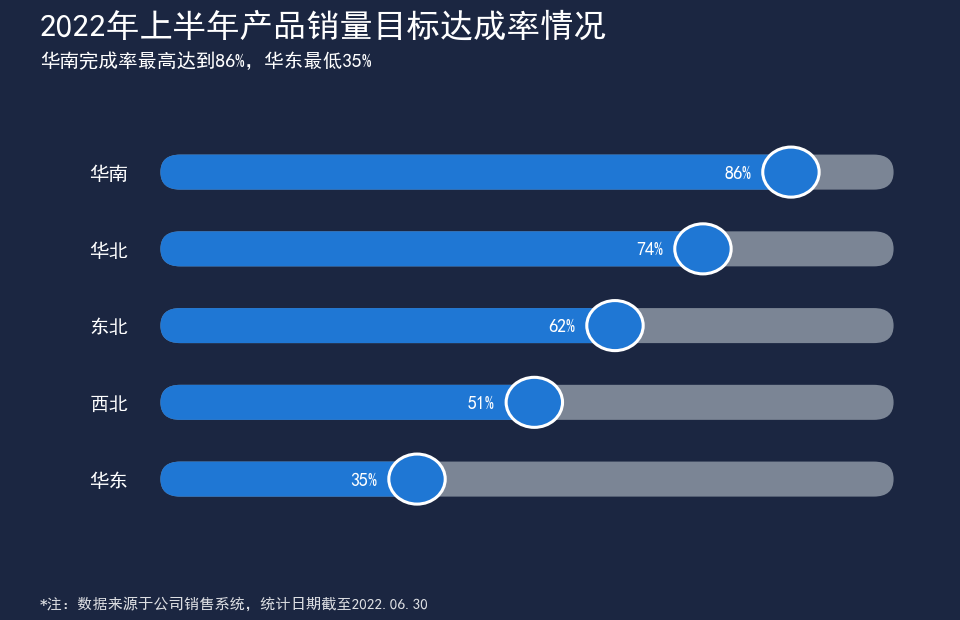

In [15]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据（来自 Excel 工作表 "29 滑珠图"，按完成率从高到低排列） ==========
regions = ['华南', '华北', '东北', '西北', '华东']
rates   = [0.86, 0.74, 0.62, 0.51, 0.35]

bg_color     = '#1B2641'
text_color   = '#FFFFFF'
track_color  = '#7B8595'      # 灰色背景条
bar_color    = '#1F77D4'      # 蓝色完成条
dot_color    = '#1F77D4'      # 圆点填充
dot_edge     = '#FFFFFF'      # 圆点白色描边

# ========== 3. 创建画布 ==========
fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis('off')

# ========== 4. 布局参数 ==========
label_x = 1.05              # 左侧文字中心
track_start = 1.6           # 胶囊条起点
track_end = 9.4             # 胶囊条终点
track_len = track_end - track_start
bar_h = 0.42                # 条高度
radius = bar_h / 2          # 圆角半径
row_y_start = 4.85          # 第一行中心 y
row_gap = 0.92              # 行间距
dot_r = 0.30                # 圆点半径

# ========== 5. 逐行绘制 ==========
for i, (region, rate) in enumerate(zip(regions, rates)):
    y = row_y_start - i * row_gap

    # ---- 5.1 区域名称（左侧） ----
    ax.text(label_x, y, region, color=text_color, fontsize=14,
            ha='center', va='center')

    # ---- 5.2 灰色胶囊背景条（代表 100%） ----
    track = FancyBboxPatch(
        (track_start, y - bar_h / 2), track_len, bar_h,
        boxstyle=f'round,pad=0,rounding_size={radius}',
        facecolor=track_color, edgecolor='none', zorder=2
    )
    ax.add_patch(track)

    # ---- 5.3 蓝色胶囊完成条（长度 = 完成率 × 总长） ----
    bar_len = track_len * rate
    bar = FancyBboxPatch(
        (track_start, y - bar_h / 2), bar_len, bar_h,
        boxstyle=f'round,pad=0,rounding_size={radius}',
        facecolor=bar_color, edgecolor='none', zorder=3
    )
    ax.add_patch(bar)

    # ---- 5.4 圆点（位于完成率位置，带白色描边） ----
    dot_x = track_start + bar_len
    dot = Circle((dot_x, y), dot_r,
                 facecolor=dot_color, edgecolor=dot_edge,
                 linewidth=2.2, zorder=5)
    ax.add_patch(dot)

    # ---- 5.5 百分比文字（圆点左侧，白色加粗） ----
    ax.text(dot_x - dot_r - 0.12, y, f'{rate*100:.0f}%',
            color=text_color, fontsize=13, fontweight='bold',
            ha='right', va='center', zorder=6)

# ========== 6. 标题与副标题 ==========
fig.text(0.06, 0.93, '2022年上半年产品销量目标达成率情况',
         color=text_color, fontsize=24, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.875,
         '华南完成率最高达到86%，华东最低35%',
         color=text_color, fontsize=14, ha='left', va='center')

# ========== 7. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 8. 布局与保存 ==========
plt.subplots_adjust(left=0.03, right=0.97, top=0.85, bottom=0.08)
plt.savefig('滑珠图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()

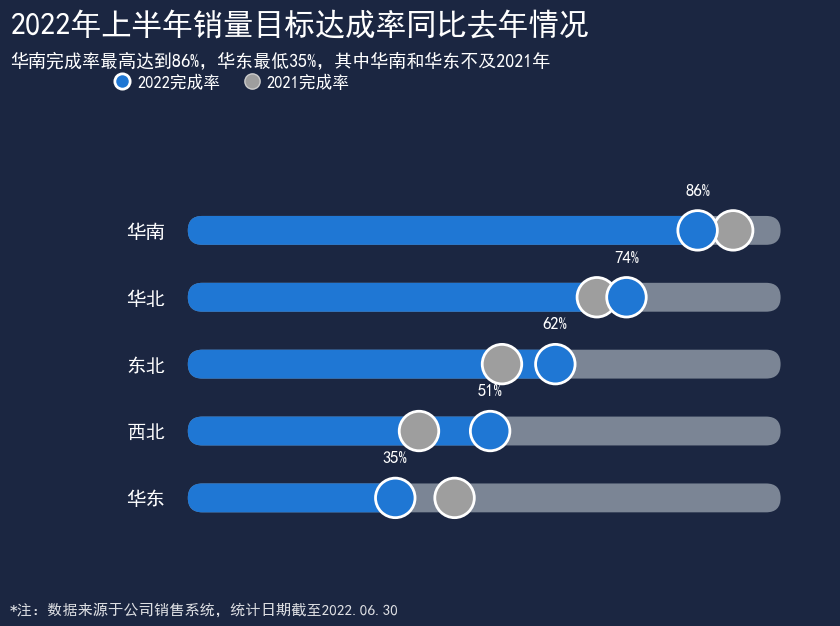

In [17]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle
from matplotlib.lines import Line2D

# ========== 1. 全局样式 ==========
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# ========== 2. 数据 ==========
regions   = ['华南', '华北', '东北', '西北', '华东']
rate_2022 = [0.86, 0.74, 0.62, 0.51, 0.35]
rate_2021 = [0.92, 0.69, 0.53, 0.39, 0.45]

bg_color    = '#1B2641'
text_color  = '#FFFFFF'
track_color = '#7B8595'
bar_color   = '#1F77D4'
dot_2022_c  = '#1F77D4'
dot_2021_c  = '#9E9E9E'
dot_edge    = '#FFFFFF'

# ========== 3. 创建画布（宽高比与数据范围匹配） ==========
fig, ax = plt.subplots(figsize=(10, 6.5))     # 10 : 6.5 ≈ xlim : ylim
fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(0, 10)
ax.set_ylim(0, 6.5)
ax.set_aspect('equal', adjustable='box')      # ★ 关键：等比例，圆即正圆
ax.axis('off')

# ========== 4. 布局参数 ==========
label_x = 1.00
track_start = 1.55
track_end = 9.35
track_len = track_end - track_start
bar_h = 0.38
radius = bar_h / 2
row_y_start = 4.55
row_gap = 0.88
dot_r = 0.26

# ========== 5. 逐行绘制 ==========
for i, (region, r22, r21) in enumerate(zip(regions, rate_2022, rate_2021)):
    y = row_y_start - i * row_gap

    # 区域名称
    ax.text(label_x, y, region, color=text_color, fontsize=14,
            ha='center', va='center')

    # 灰色胶囊轨道
    track = FancyBboxPatch(
        (track_start, y - bar_h / 2), track_len, bar_h,
        boxstyle=f'round,pad=0,rounding_size={radius}',
        facecolor=track_color, edgecolor='none', zorder=2
    )
    ax.add_patch(track)

    # 蓝色 2022 完成条
    bar_len = track_len * r22
    bar = FancyBboxPatch(
        (track_start, y - bar_h / 2), bar_len, bar_h,
        boxstyle=f'round,pad=0,rounding_size={radius}',
        facecolor=bar_color, edgecolor='none', zorder=3
    )
    ax.add_patch(bar)

    # 2021 灰色圆点
    dot21_x = track_start + track_len * r21
    ax.add_patch(Circle((dot21_x, y), dot_r,
                        facecolor=dot_2021_c, edgecolor=dot_edge,
                        linewidth=2.0, zorder=4))

    # 2022 蓝色圆点
    dot22_x = track_start + bar_len
    ax.add_patch(Circle((dot22_x, y), dot_r,
                        facecolor=dot_2022_c, edgecolor=dot_edge,
                        linewidth=2.0, zorder=5))

    # 百分比文字
    ax.text(dot22_x, y + dot_r + 0.18, f'{r22*100:.0f}%',
            color=text_color, fontsize=12, fontweight='bold',
            ha='center', va='bottom', zorder=6)

# ========== 6. 图例 ==========
legend_elements = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=dot_2022_c, markeredgecolor=dot_edge,
           markeredgewidth=2.0, markersize=11, label='2022完成率'),
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor=dot_2021_c, markeredgecolor='#CCCCCC',
           markeredgewidth=1.0, markersize=11, label='2021完成率'),
]
ax.legend(handles=legend_elements, loc='upper left',
          bbox_to_anchor=(0.04, 1.05), frameon=False,
          labelcolor=text_color, fontsize=12, ncol=2,
          handlelength=0.8, columnspacing=1.5, handletextpad=0.5)

# ========== 7. 标题与副标题 ==========
fig.text(0.06, 0.94, '2022年上半年销量目标达成率同比去年情况',
         color=text_color, fontsize=22, fontweight='bold',
         ha='left', va='center')
fig.text(0.06, 0.885,
         '华南完成率最高达到86%，华东最低35%，其中华南和华东不及2021年',
         color=text_color, fontsize=13, ha='left', va='center')

# ========== 8. 底部注释 ==========
fig.text(0.06, 0.04,
         '*注：数据来源于公司销售系统，统计日期截至2022.06.30',
         color=text_color, fontsize=11, ha='left', va='center', alpha=0.85)

# ========== 9. 布局与保存 ==========
plt.subplots_adjust(left=0.04, right=0.96, top=0.85, bottom=0.09)
plt.savefig('对比滑珠图_复现.png', dpi=300,
            bbox_inches='tight', facecolor=bg_color)
plt.show()